# División temporal y baseline — Cancelaciones hoteleras

## Alcance de fase 4
Implementar la división temporal propuesta, ajustar un pipeline de regresión logística únicamente con entrenamiento y evaluarlo en validación frente a un clasificador mayoritario. Se revisaron los informes de fases 1–3, preparación y módulos existentes. Se mantienen los 14 predictores, todas las filas y sus reglas de calidad. No se entrena ningún modelo avanzado ni se optimizan hiperparámetros o umbrales.

La prueba se audita en dimensiones, fechas y clases como requiere la tarea, y se transforma con parámetros de entrenamiento para comprobar compatibilidad. **No se generan predicciones ni métricas de prueba.** El EDA previo ya exploró todo el archivo: esta reserva de prueba es prospectiva respecto al baseline, no completamente ajena al análisis anterior.

**Histórico v1:** estas salidas pertenecen a la fase 4 y no son el baseline vigente tras la corrección 4.2. Al reproducir este notebook, las reejecuciones v1 se escriben en reports/historico/protocolo_v1/reproduccion para proteger el histórico congelado y el protocolo activo. Consultar protocolo_temporal.ipynb y fase_4_2_protocolo_temporal.md para v2.

## 1. Revisión de preparación y reglas fijadas antes del ajuste
**Pregunta:** ¿se preservan filas, etiqueta y aislamiento de metadatos y campos dudosos?

In [1]:
from pathlib import Path
import sys
import hashlib
import json
import io
import unittest
import importlib.metadata
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.metrics import roc_curve
from sklearn.exceptions import NotFittedError
from sklearn.utils.validation import check_is_fitted

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data/raw/hotel_bookings.csv").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.features import FEATURES, LEAKAGE_FEATURES, UNCERTAIN_FEATURES
from src.baseline import load_baseline_data, build_logistic_pipeline, fit_and_validate, write_baseline_report, legacy_output_dir
from src.preparation import TEMPORAL_PLAN

REPORT_PATH = legacy_output_dir(PROJECT_ROOT)
FIGURE_PATH = REPORT_PATH / "figures"
FIGURE_PATH.mkdir(exist_ok=True)
protected = [PROJECT_ROOT / "data/raw/hotel_bookings.csv", PROJECT_ROOT / "data/processed/hotel_bookings_prepared.csv",
             PROJECT_ROOT / "notebooks/preparacion.ipynb", PROJECT_ROOT / "reports/fase_3_preparacion.md"]
before_hashes = {str(path): hashlib.sha256(path.read_bytes()).hexdigest() for path in protected}
X, y, metadata, assigned, split_table, hotel_months = load_baseline_data(PROJECT_ROOT)
assert X.shape == (119390, 14) and y.name == "is_canceled"
assert not any(column.startswith("meta_") for column in X)
assert not (set(X) & set(LEAKAGE_FEATURES + UNCERTAIN_FEATURES + ["is_canceled"]))
fresh_pipeline = build_logistic_pipeline()
try:
    check_is_fitted(fresh_pipeline)
except NotFittedError:
    print("Pipeline nuevo: no hay ajuste previo sobre el dataset completo.")
else:
    raise AssertionError("Se esperaba un pipeline sin ajustar.")
print("Predictores:", FEATURES)
print("Filas conservadas:", len(X), "; etiqueta:", y.name)
display(X.isna().sum().to_frame("nulos_antes_del_fit"))

Pipeline nuevo: no hay ajuste previo sobre el dataset completo.
Predictores: ['lead_time', 'total_nights', 'adults', 'children', 'babies', 'children_missing', 'hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'customer_type']
Filas conservadas: 119390 ; etiqueta: is_canceled


,nulos_antes_del_fit
lead_time,0
total_nights,0
adults,0
children,4
babies,0
children_missing,0
hotel,0
arrival_date_month,0
meal,0
country,488


**Interpretación.** La entrada conserva 119.390 reservas y los 14 predictores de fase 3. Niños y país mantienen sus nulos hasta el fit de entrenamiento. Etiqueta, estados finales, variables inciertas y metadatos no llegan al preprocesador. El indicador de niños desconocidos es determinista; las estadísticas aún no se han aprendido.

## 2. Auditoría de cortes, clases y cobertura anual
**Pregunta:** ¿los cortes son viables y qué reservas disponen de etiqueta a tiempo?

,particion,registros,no_canceladas,canceladas,tasa_cancelacion,proxy_min,proxy_max,llegada_min,llegada_max,madurez_min,madurez_max
0,entrenamiento,48428,31088,17340,0.3581,2013-06-24,2016-06-29,2015-07-01,2016-06-29,2015-07-02,2016-06-30
1,validacion,14011,10344,3667,0.2617,2016-07-01,2016-12-30,2016-07-01,2016-12-30,2016-07-03,2016-12-31
2,prueba_reservada,26565,18163,8402,0.3163,2017-01-01,2017-08-31,2017-01-01,2017-08-31,2017-01-03,2017-09-15
3,no_madura_entrenamiento,17825,9348,8477,0.4756,2015-02-20,2016-06-30,2016-06-14,2017-08-29,2016-07-01,2017-08-31
4,no_madura_validacion,12561,6223,6338,0.5046,2016-07-01,2016-12-31,2016-12-13,2017-08-31,2017-01-01,2017-09-12


meta_arrival_date,1,2,3,4,5,6,7,8,9,10,11,12
hotel,,,,,,,,,,,,
City Hotel,1364,2371,3046,3561,3676,3472,1398,2480,3529,3386,1235,1654
Resort Hotel,884,1520,1778,1867,1802,1091,1378,1409,1585,1571,1105,1266


,reservas_entrenamiento
meta_arrival_date,
2015-07,2776
2015-08,3889
2015-09,5114
2015-10,4957
2015-11,2340
2015-12,2920
2016-01,2248
2016-02,3891
2016-03,4824


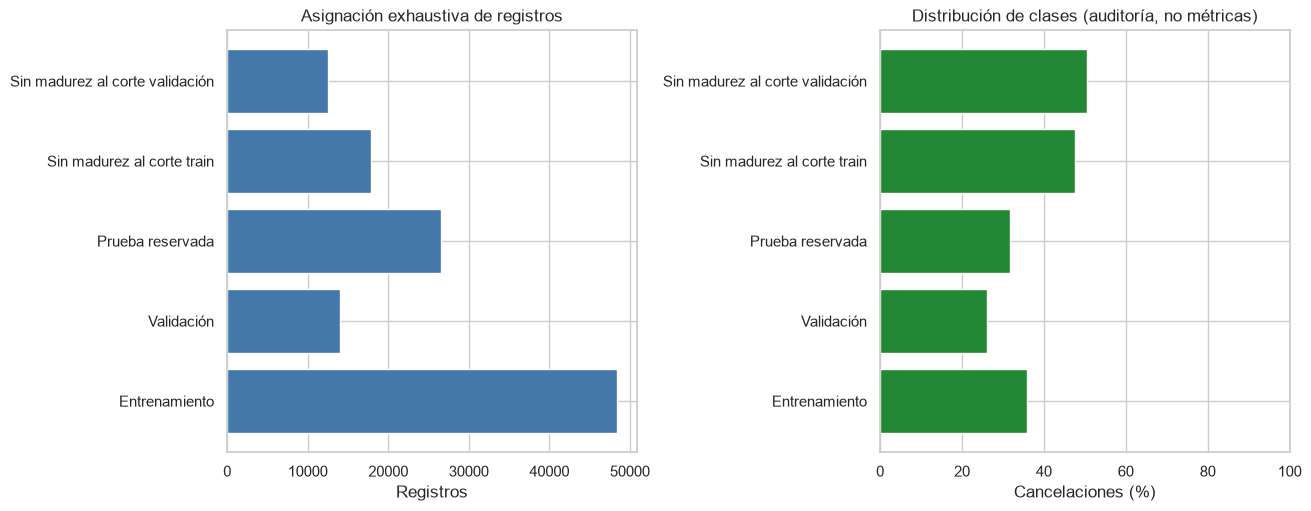

**Resultado previo al entrenamiento.** Cortes fijados en 2016-07-01 y 2017-01-01. Hay 48,428 reservas de entrenamiento, 14,011 de validación, 26,565 de prueba y 30,386 apartadas por madurez. Entrenamiento incluye doce meses consecutivos de llegadas, julio de 2015–junio de 2016, en ambos hoteles; junio queda truncado por la madurez estricta. No hay cruces de filas o grupos duplicados. Las tablas muestran ambas clases y sus tasas sin utilizar la prueba para elegir configuración.

In [2]:
display(split_table)
display(hotel_months)
train_mask = assigned.eq("entrenamiento")
valid_mask = assigned.eq("validacion")
test_mask = assigned.eq("prueba_reservada")
train_month = pd.to_datetime(metadata.loc[train_mask, "meta_arrival_date"]).dt.to_period("M")
display(train_month.value_counts().sort_index().to_frame("reservas_entrenamiento"))
assert hotel_months.gt(0).all().all()
assert assigned.notna().all() and len(assigned) == len(X)
assert not (train_mask & valid_mask).any() and not (train_mask & test_mask).any() and not (valid_mask & test_mask).any()
assert metadata.assign(particion=assigned).groupby("meta_duplicate_group").particion.nunique().max() == 1
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
labels = ["Entrenamiento", "Validación", "Prueba reservada", "Sin madurez al corte train", "Sin madurez al corte validación"]
axes[0].barh(labels, split_table.registros, color="#4477AA")
axes[0].set(title="Asignación exhaustiva de registros", xlabel="Registros")
axes[1].barh(labels, split_table.tasa_cancelacion * 100, color="#228833")
axes[1].set(title="Distribución de clases (auditoría, no métricas)", xlabel="Cancelaciones (%)", xlim=(0, 100))
fig.savefig(FIGURE_PATH / "baseline_01_particiones.png", dpi=140, bbox_inches="tight")
plt.show(); plt.close(fig)
not_mature = assigned.str.startswith("no_madura")
display(Markdown(f"**Resultado previo al entrenamiento.** Cortes fijados en {TEMPORAL_PLAN['corte_validacion']} y {TEMPORAL_PLAN['corte_prueba']}. Hay {int(train_mask.sum()):,} reservas de entrenamiento, {int(valid_mask.sum()):,} de validación, {int(test_mask.sum()):,} de prueba y {int(not_mature.sum()):,} apartadas por madurez. Entrenamiento incluye doce meses consecutivos de llegadas, julio de 2015–junio de 2016, en ambos hoteles; junio queda truncado por la madurez estricta. No hay cruces de filas o grupos duplicados. Las tablas muestran ambas clases y sus tasas sin utilizar la prueba para elegir configuración."))

### Decisión metodológica antes de entrenar
Se mantienen los cortes de fase 3 y se materializan **cinco grupos**, incluyendo dos de auditoría de madurez. Ninguna reserva se borra o reasigna a un periodo posterior solo para aumentar el entrenamiento.

La madurez es `max(llegada + noches, fecha_estado_final) + 1 día < corte`. Se exige antes del 01/07/2016 para entrenamiento y antes del 01/01/2017 para validación. La fecha final solo restringe retrospectivamente cuándo sería elegible la etiqueta, no es predictor. Es una cota conservadora no demostrada como disponibilidad real en el hotel.

La condición de madurez deja fuera de la validación reservas con llegadas lejanas y favorece menor antelación. Por tanto, las métricas describen **el subconjunto elegible**, no todas las reservas creadas en ese semestre. Los grupos apartados tienen tasas diferentes; no son una muestra aleatoria de ausencias. La corrección operativa es mantenerlos explícitamente en el manifiesto y limitar el alcance de la estimación; no reutilizar resultados futuros ni afirmar que la censura se ha resuelto.

No se dispone de hora/fecha de creación observada. El proxy puede cambiar si llegada o lead_time fueron actualizados; su mínimo en 2013 no significa que haya un histórico completo de altas desde 2013. Los empates de fecha se mantienen juntos. Las llegadas comienzan en julio de 2015 y terminan en agosto de 2017; la prueba abarca solo parte del último año. Su madurez máxima es septiembre de 2017; antes de evaluarla en otra fase habrá que documentar seguimiento/extracción suficiente.

## 3. Pipeline y referencias fijadas
**Pregunta:** ¿cómo aprender transformaciones sin información posterior?

In [3]:
print(fresh_pipeline)
print("Umbral fijado: 0.5; C=1; solver=lbfgs; sin ponderación de clases; semilla=42.")
print("max_iter=2000 es un límite numérico previo, no una búsqueda de hiperparámetros.")

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(sparse_threshold=1.0,
                                   transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(keep_empty_features=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['lead_time', 'total_nights',
                                                   'adults', 'children',
                                                   'babies',
                                                   'children_missing']),
                                                 ('categorical',
                                             

**Elección.** La regresión logística es una primera referencia sencilla: estima una puntuación probabilística mediante un modelo lineal en log-odds sobre características codificadas. No captura automáticamente todas las interacciones o relaciones no lineales y su probabilidad no se da por calibrada.

Se reutiliza `build_preprocessor`: mediana numérica, escalado estándar, categoría Desconocido y OneHotEncoder con categorías nuevas ignoradas. El pipeline completo se ajustará solo con entrenamiento. Las medianas, medias y vocabularios se contrastarán contra ese conjunto, y se comprobará que transformar validación/prueba no los cambia. Ninguna columna numérica está completamente ausente en entrenamiento, por lo que no se activa el relleno de una columna totalmente vacía.

El trivial aprende únicamente la clase mayoritaria de **entrenamiento**, con DummyClassifier(strategy='most_frequent'). No se infiere la regla desde validación. Para sus métricas, precision y F1 sin predicciones positivas se representan como cero, con zero_division=0; eso no implica que exista una precision estimable entre alertas inexistentes. Su ROC-AUC constante será 0,5 si hay ambas clases.

## 4. Ajuste único y evaluación en validación
**Pregunta:** ¿la logística aporta información respecto a predecir siempre la clase mayoritaria?

In [4]:
model, metrics, audit, validation_predictions = fit_and_validate(X, y, assigned)
metric_table = pd.DataFrame({name: {key: value for key, value in values.items() if key != "matriz_confusion"} for name, values in metrics.items()}).T
display(metric_table)
display(pd.Series({key: audit[key] for key in ["n_train_fit", "n_valid_evaluadas", "n_test_solo_transformadas", "n_features_transformadas", "iteraciones_logistica", "advertencias_fit", "estadisticas_solo_train_verificadas", "estadisticas_inmutables_al_transformar", "test_predict_ejecutado"]}, name="auditoria").to_frame())
validation_predictions.insert(0, "meta_row_id", metadata.loc[valid_mask, "meta_row_id"])
validation_predictions.to_csv(REPORT_PATH / "baseline_predicciones_validacion.csv", index=False)
result = {"evaluacion": "solo validación", "parametros_fijados": audit["parametros"], "metricas": metrics,
          "auditoria_fit": audit, "cortes": {"validacion": TEMPORAL_PLAN["corte_validacion"], "prueba": TEMPORAL_PLAN["corte_prueba"]},
          "particiones": split_table.to_dict("records"), "prueba_evaluada": False,
          "sha256_original": before_hashes[str(PROJECT_ROOT / "data/raw/hotel_bookings.csv")],
          "sha256_preparado": before_hashes[str(PROJECT_ROOT / "data/processed/hotel_bookings_prepared.csv")]}
(REPORT_PATH / "baseline_resultados.json").write_text(json.dumps(result, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

,accuracy,precision,recall,f1,roc_auc
mayoritario,0.7383,0.0000,0.0000,0.0000,0.5000
regresion_logistica,0.7443,0.5336,0.1841,0.2737,0.7004


,auditoria
n_train_fit,48428
n_valid_evaluadas,14011
n_test_solo_transformadas,26565
n_features_transformadas,191
iteraciones_logistica,[131]
advertencias_fit,[]
estadisticas_solo_train_verificadas,True
estadisticas_inmutables_al_transformar,True
test_predict_ejecutado,False


11151

## 5. Errores y capacidad de ordenación
**Pregunta:** ¿qué reservas pasan desapercibidas y cuántas alertas resultan falsas?

Las matrices tienen filas de clase real y columnas de predicción, orden 0=no cancelación y 1=cancelación. Se representan recuentos, no porcentajes sobre bases distintas.

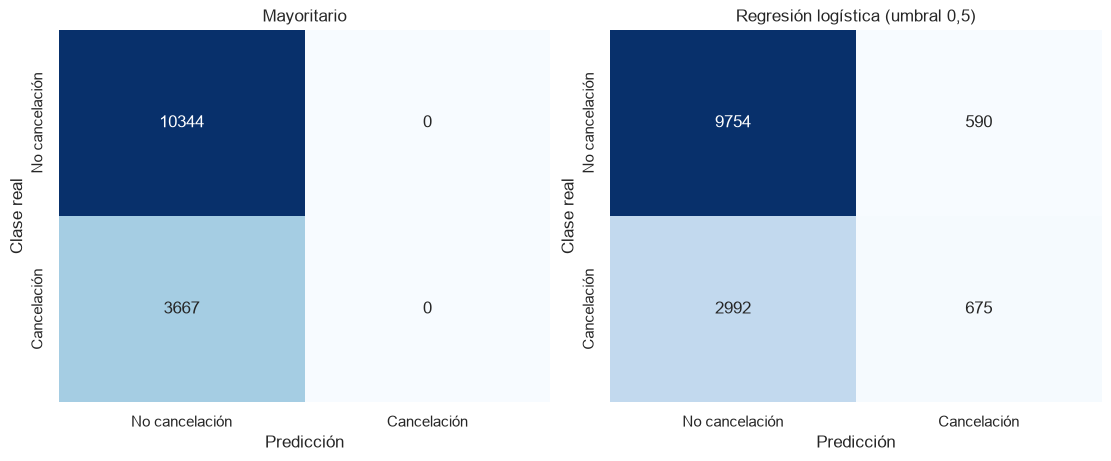

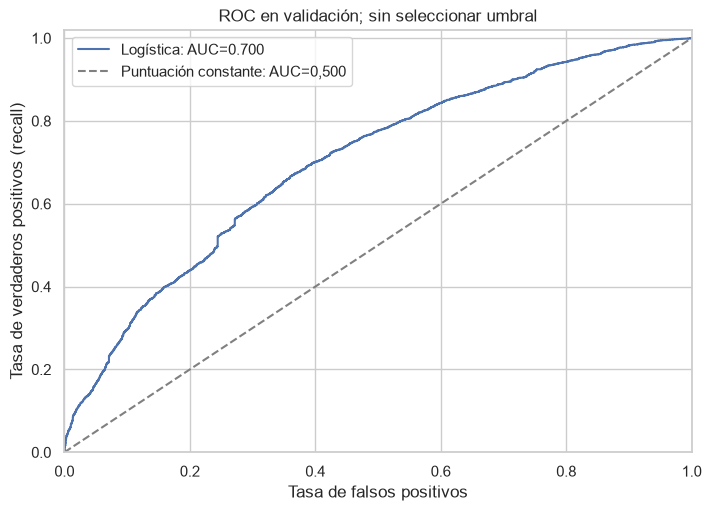


**Interpretación del resultado ejecutado.** La logística obtiene accuracy 74.43%, precision 53.36%, recall 18.41%, F1 0.2737 y ROC-AUC 0.7004. El trivial tiene accuracy 73.83%, recall 0.00%, F1 0.0000 y ROC-AUC 0.5000. La diferencia de accuracy es 0.61 puntos; la comparación completa está en la tabla, sin equiparar “supera al trivial” con “listo para operar”.

- **675 verdaderos positivos:** reservas canceladas detectadas por la alerta.
- **2,992 falsos negativos:** cancelaciones que pasan desapercibidas; pueden perjudicar la planificación si se confía en que esas reservas se mantendrán.
- **590 falsos positivos:** alertas sobre reservas que finalmente se mantienen; podrían consumir tiempo de seguimiento o generar contacto innecesario.
- **9,754 verdaderos negativos:** reservas no canceladas sin alerta.

Entre alertas, 53.36% corresponden a cancelaciones observadas. Se detecta 18.41% de las cancelaciones elegibles y queda sin detectar 81.59%. Mejorar recall suele implicar más alertas falsas al cambiar umbral, pero **no se ha probado ni elegido otro umbral**. F1 resume precision/recall sin incorporar costes de negocio; ROC-AUC mide ordenación, no calibración ni beneficio. Sin costes y capacidad de seguimiento no se puede declarar óptimo 0,5 ni rentable el modelo.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
for ax, (name, values) in zip(axes, metrics.items()):
    sns.heatmap(values["matriz_confusion"], annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["No cancelación", "Cancelación"], yticklabels=["No cancelación", "Cancelación"], ax=ax)
    ax.set(title="Mayoritario" if name == "mayoritario" else "Regresión logística (umbral 0,5)", xlabel="Predicción", ylabel="Clase real")
fig.savefig(FIGURE_PATH / "baseline_02_confusion_validacion.png", dpi=140, bbox_inches="tight")
plt.show(); plt.close(fig)
fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
fpr, tpr, _ = roc_curve(y.loc[valid_mask], validation_predictions.probabilidad_logistica)
ax.plot(fpr, tpr, label=f"Logística: AUC={metrics['regresion_logistica']['roc_auc']:.3f}")
ax.plot([0, 1], [0, 1], "--", color="gray", label="Puntuación constante: AUC=0,500")
ax.set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos (recall)", title="ROC en validación; sin seleccionar umbral", xlim=(0, 1), ylim=(0, 1.02))
ax.legend()
fig.savefig(FIGURE_PATH / "baseline_03_roc_validacion.png", dpi=140, bbox_inches="tight")
plt.show(); plt.close(fig)
logistic = metrics["regresion_logistica"]
trivial = metrics["mayoritario"]
tn, fp, fn, tp = np.array(logistic["matriz_confusion"]).ravel()
display(Markdown(f"""
**Interpretación del resultado ejecutado.** La logística obtiene accuracy {logistic['accuracy']:.2%}, precision {logistic['precision']:.2%}, recall {logistic['recall']:.2%}, F1 {logistic['f1']:.4f} y ROC-AUC {logistic['roc_auc']:.4f}. El trivial tiene accuracy {trivial['accuracy']:.2%}, recall {trivial['recall']:.2%}, F1 {trivial['f1']:.4f} y ROC-AUC {trivial['roc_auc']:.4f}. La diferencia de accuracy es {(logistic['accuracy']-trivial['accuracy'])*100:.2f} puntos; la comparación completa está en la tabla, sin equiparar “supera al trivial” con “listo para operar”.

- **{tp:,} verdaderos positivos:** reservas canceladas detectadas por la alerta.
- **{fn:,} falsos negativos:** cancelaciones que pasan desapercibidas; pueden perjudicar la planificación si se confía en que esas reservas se mantendrán.
- **{fp:,} falsos positivos:** alertas sobre reservas que finalmente se mantienen; podrían consumir tiempo de seguimiento o generar contacto innecesario.
- **{tn:,} verdaderos negativos:** reservas no canceladas sin alerta.

Entre alertas, {logistic['precision']:.2%} corresponden a cancelaciones observadas. Se detecta {logistic['recall']:.2%} de las cancelaciones elegibles y queda sin detectar {1-logistic['recall']:.2%}. Mejorar recall suele implicar más alertas falsas al cambiar umbral, pero **no se ha probado ni elegido otro umbral**. F1 resume precision/recall sin incorporar costes de negocio; ROC-AUC mide ordenación, no calibración ni beneficio. Sin costes y capacidad de seguimiento no se puede declarar óptimo 0,5 ni rentable el modelo.
"""))

## 6. Limitaciones y decisión para la siguiente fase
**Pregunta:** ¿qué podemos concluir sin sobreinterpretar esta referencia?

El modelo puede tener señal útil frente a una predicción constante y aun así ser insuficiente para negocio. La logística impone aditividad en log-odds, no modela automáticamente interacciones complejas, y el umbral 0,5 puede favorecer la clase mayoritaria. No se usaron reponderación ni remuestreo; sus efectos no se han comparado. Las clases cambian entre entrenamiento, validación y reservas apartadas, de modo que accuracy y precision dependen de composición y prevalencia.

Las métricas corresponden a validación con etiquetas maduras en el corte; no a todo el semestre ni a prueba. Las reservas largas quedan más expuestas a quedar fuera por madurez. Los duplicados se mantienen: no cruzan particiones, pero pueden sobreponderar patrones y reducir el tamaño efectivo. No se construyen intervalos suponiendo independencia de reservas sin justificarla.

Sigue sin acreditarse que los campos conservados sean snapshots iniciales. El proxy de creación y la cota de disponibilidad de etiqueta son aproximaciones, no logs históricos. El EDA previo expuso el archivo completo. Hace falta documentación temporal y una validación externa/prospectiva para afirmar utilidad en producción.

**Siguiente paso propuesto, pendiente de autorización:** revisar el alcance del baseline y la elegibilidad temporal; después, en la fase que autorice el usuario, comparar modelos del curso con estas mismas particiones y preprocesamiento dentro de cada ajuste. Cualquier futura elección de modelo/umbral debe usar únicamente entrenamiento/validación; prueba se reserva para una evaluación final. No se ejecuta esa comparación aquí.

## 7. Pruebas e integridad
**Pregunta:** ¿quedó trazabilidad verificable del ajuste y de los datos reservados?

In [6]:
suite = unittest.defaultTestLoader.discover(str(PROJECT_ROOT / "tests"))
log = io.StringIO()
tests = unittest.TextTestRunner(stream=log, verbosity=2).run(suite)
print(log.getvalue())
assert tests.wasSuccessful()
for filename, checksum in before_hashes.items():
    assert hashlib.sha256(Path(filename).read_bytes()).hexdigest() == checksum
references = json.loads((PROJECT_ROOT / "reports/verificacion_referencias.json").read_text(encoding="utf-8"))["antes"]
verified, unavailable = 0, 0
for filename, expected in references.items():
    path = Path(filename)
    if not path.is_file():
        unavailable += 1
        continue
    with path.open("rb") as file:
        assert hashlib.file_digest(file, "sha256").hexdigest() == expected
    verified += 1
verification = {"tests": tests.testsRun, "fallos": len(tests.failures), "errores": len(tests.errors),
    "csv_original_intacto": True, "csv_preparado_intacto": True, "notebook_preparacion_intacto": True,
    "referencias_sin_cambios": verified, "referencias_no_disponibles": unavailable,
    "estadisticas_solo_entrenamiento": True, "test_solo_auditoria_y_transform": True,
    "predicciones_test_generadas": False, "metricas_test_calculadas": False,
    "umbral_fijado": 0.5, "busqueda_hiperparametros": False, "modelos": ["DummyClassifier(most_frequent)", "LogisticRegression"],
    "cwd_ejecucion": "raiz" if Path.cwd() == PROJECT_ROOT else "notebooks",
    "versiones": {"python": platform.python_version(), **{p: importlib.metadata.version(p) for p in ["pandas", "numpy", "scikit-learn", "matplotlib", "seaborn", "nbclient"]}}}
(REPORT_PATH / "baseline_verificacion.json").write_text(json.dumps(verification, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
display(pd.Series(verification, name="verificacion").to_frame())
print("Fin de fase 4. La prueba permanece sin predicciones ni evaluación; no se continúa sin autorización.")
print("Informe generado:", write_baseline_report(PROJECT_ROOT).relative_to(PROJECT_ROOT))

test_confusion_orientation_and_trivial_auc (test_baseline.BaselineTests.test_confusion_orientation_and_trivial_auc) ... ok
test_dates_and_maturity_boundaries (test_baseline.BaselineTests.test_dates_and_maturity_boundaries) ... ok
test_duplicate_group_cannot_cross_partitions (test_baseline.BaselineTests.test_duplicate_group_cannot_cross_partitions) ... ok
test_invalid_dates_and_cut_order_fail (test_baseline.BaselineTests.test_invalid_dates_and_cut_order_fail) ... ok
test_all_rows_and_duplicates_preserved_without_mutation (test_preparation.PreparationTests.test_all_rows_and_duplicates_preserved_without_mutation) ... ok
test_anomalies_and_unknowns_not_guessed (test_preparation.PreparationTests.test_anomalies_and_unknowns_not_guessed) ... ok
test_no_scaling_option_and_temporal_metadata (test_preparation.PreparationTests.test_no_scaling_option_and_temporal_metadata) ... ok
test_target_and_future_values_cannot_change_features (test_preparation.PreparationTests.test_target_and_future_values_c

,verificacion
tests,9
fallos,0
errores,0
csv_original_intacto,True
csv_preparado_intacto,True
notebook_preparacion_intacto,True
referencias_sin_cambios,105
referencias_no_disponibles,0
estadisticas_solo_entrenamiento,True
test_solo_auditoria_y_transform,True


Fin de fase 4. La prueba permanece sin predicciones ni evaluación; no se continúa sin autorización.
Informe generado: reports\fase_4_baseline.md
